# AI Security Literacy (AISL) — Empirical Grounding Notebook

Runs on **real, public datasets**. No synthetic data.

- **Tier 2 (technical dimensions D3–D5)** — fully runnable here: pulls TruthfulQA, RealToxicityPrompts, BBQ from Hugging Face and runs a real FGSM sweep.
- **Tier 1 (attitudinal dimensions D1,D2,D6)** — a real analysis *pipeline*; it runs once you place the RAND/Harvard/Gallup micro-data files in Google Drive and map the codebook variables (marked `TODO`).

Outputs are written to `figures/` (300-dpi **JPG** for Overleaf) and `tables/` for the LaTeX manuscript (`AISL_article.tex`).



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 0. Setup


In [1]:
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
# Overleaf-ready, publication-quality raster output
FIGDIR='figures'  # matches \graphicspath{{figures/}} in the LaTeX
os.makedirs(FIGDIR, exist_ok=True); os.makedirs('tables', exist_ok=True)
plt.rcParams.update({'figure.dpi':300,'savefig.dpi':300,'savefig.format':'jpg',
                     'font.size':11,'axes.titlesize':12,'figure.autolayout':True})
def savefig(name):
    # write high-resolution JPG (300 dpi) into figures/ for Overleaf
    plt.savefig(os.path.join(FIGDIR, name+'.jpg'), dpi=300, format='jpg', bbox_inches='tight', pil_kwargs={'quality':95})
    print('saved', os.path.join(FIGDIR, name+'.jpg'))


In [2]:
# Mount Google Drive (for Tier 1 micro-data you download yourself).
try:
    from google.colab import drive; drive.mount('/content/drive')
    DRIVE='/content/drive/MyDrive/AISL_data'   # <-- put your downloaded survey files here
except Exception as e:
    DRIVE='./AISL_data'; print('Not on Colab; using local', DRIVE)
os.makedirs(DRIVE, exist_ok=True); print('Data folder:', DRIVE)


Mounted at /content/drive
Data folder: /content/drive/MyDrive/AISL_data


---
# TIER 2 — Phenomenon grounding for D3–D5 (fully runnable)
Establishes that the technical dimensions name **real, measured** phenomena.


### D3 — Threat & manipulation: RealToxicityPrompts toxicity distribution
Public: `allenai/real-toxicity-prompts` (Apache-2.0). ~100k web prompts scored by Perspective API.


README.md:   0%|          | 0.00/4.22k [00:00<?, ?B/s]

prompts.jsonl:   0%|          | 0.00/67.7M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/99442 [00:00<?, ? examples/s]

n = 19877 | mean = 0.087 | % > 0.5 = 0.1
saved figures/d3_rtp_toxicity.jpg


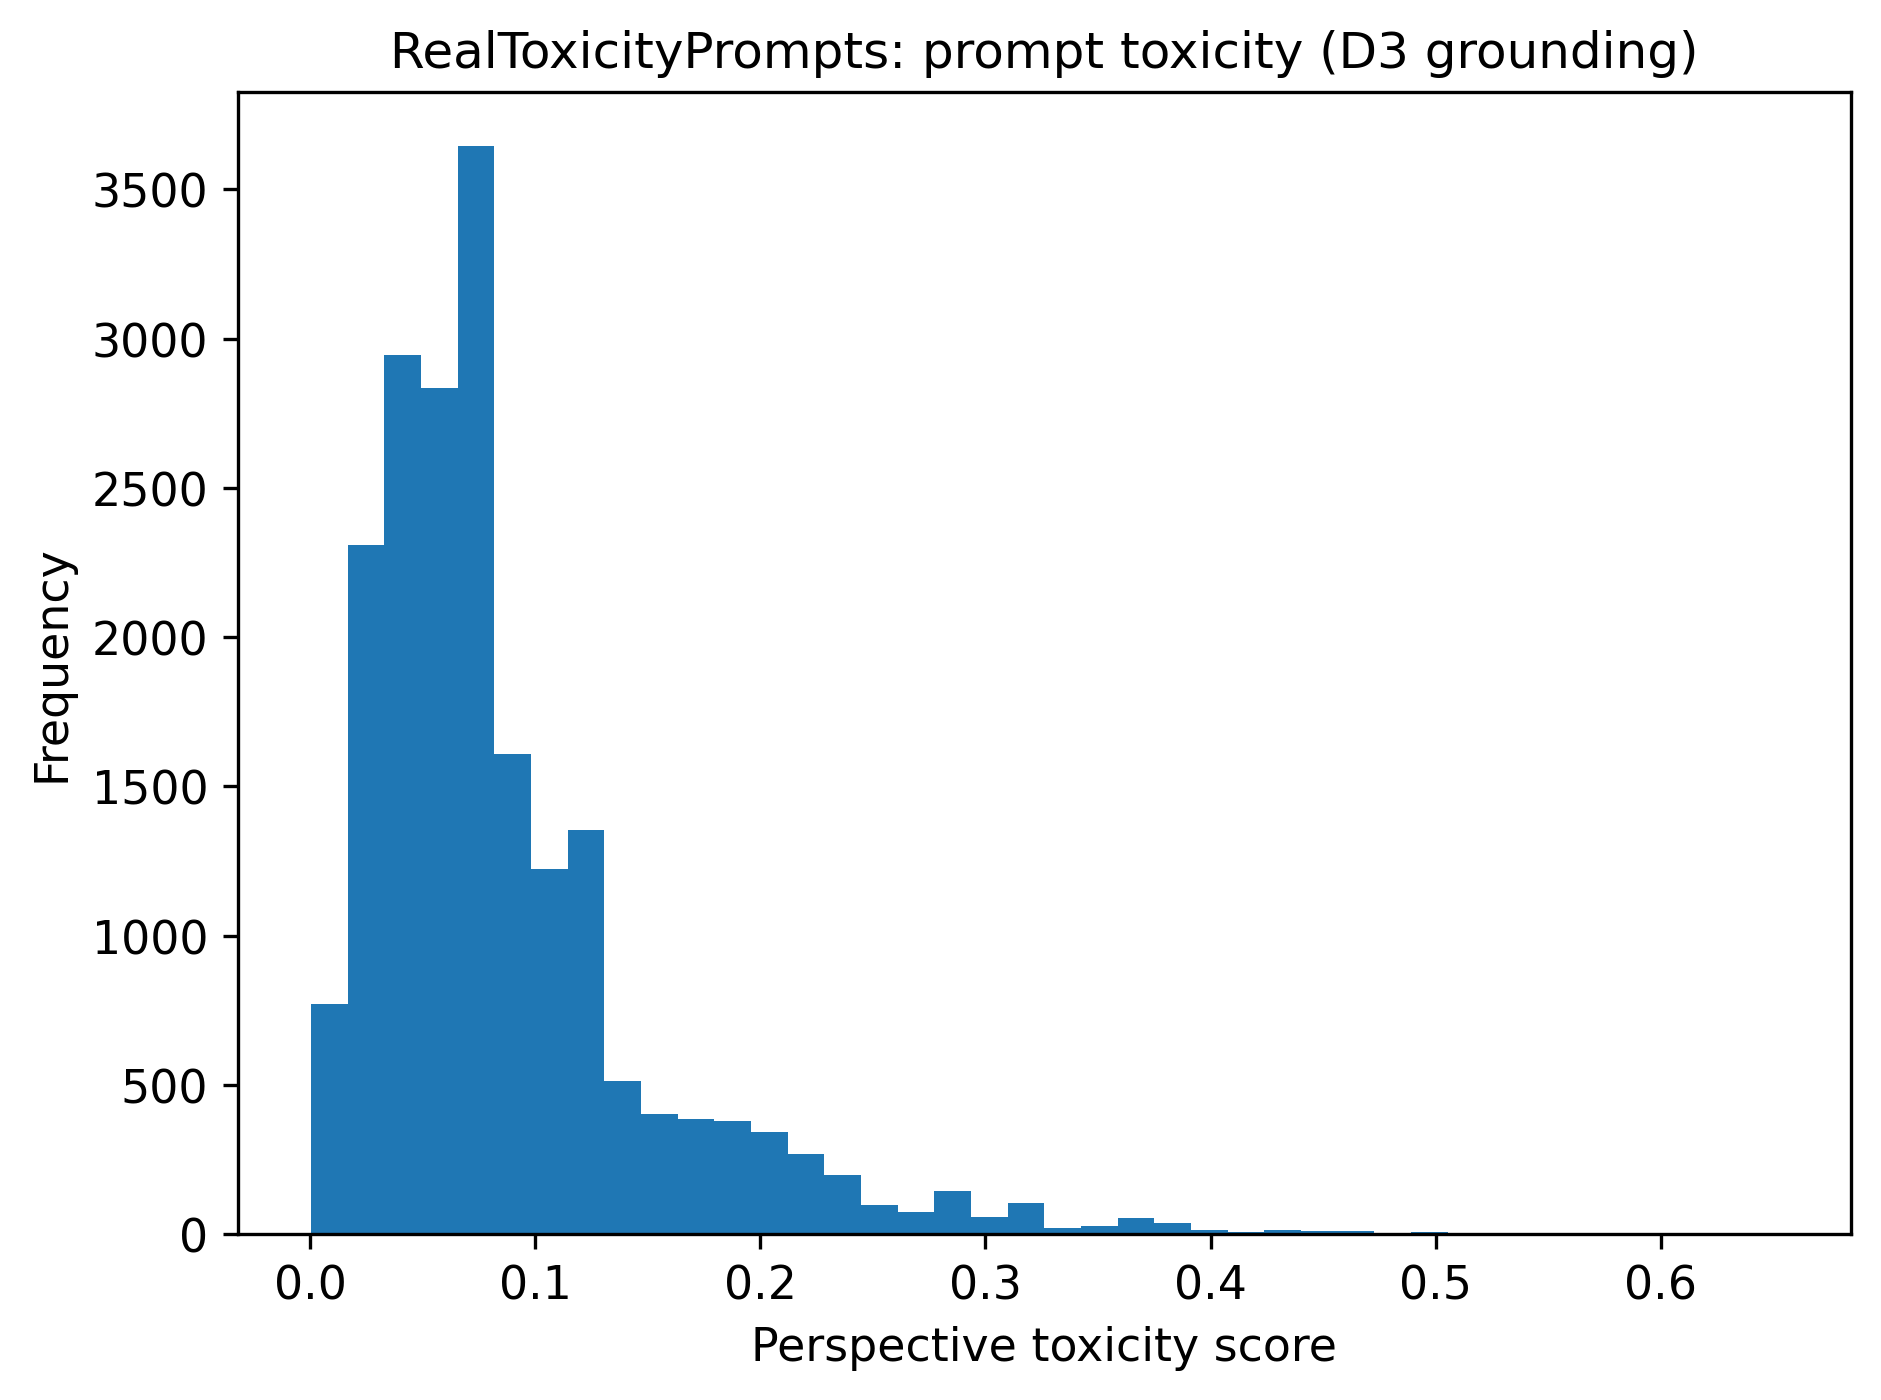

In [3]:
from datasets import load_dataset
rtp = load_dataset('allenai/real-toxicity-prompts', split='train')
tox = [ (r['prompt'] or {}).get('toxicity') for r in rtp.select(range(20000)) ]
tox = pd.Series([t for t in tox if t is not None], name='prompt_toxicity')
print('n =', len(tox), '| mean =', round(tox.mean(),3), '| % > 0.5 =', round((tox>0.5).mean()*100,1))
ax = tox.plot(kind='hist', bins=40, title='RealToxicityPrompts: prompt toxicity (D3 grounding)')
ax.set_xlabel('Perspective toxicity score'); plt.tight_layout(); savefig('d3_rtp_toxicity'); plt.show()


### D4 — Trust calibration: TruthfulQA (misconception susceptibility)
Public: `truthfulqa/truthful_qa` (Apache-2.0). 817 questions across 38 categories crafted so humans often answer falsely.


README.md:   0%|          | 0.00/9.59k [00:00<?, ?B/s]

generation/validation-00000-of-00001.par(…):   0%|          | 0.00/223k [00:00<?, ?B/s]

Generating validation split:   0%|          | 0/817 [00:00<?, ? examples/s]

n questions = 817 | n categories = 38
saved figures/d4_truthfulqa_categories.jpg


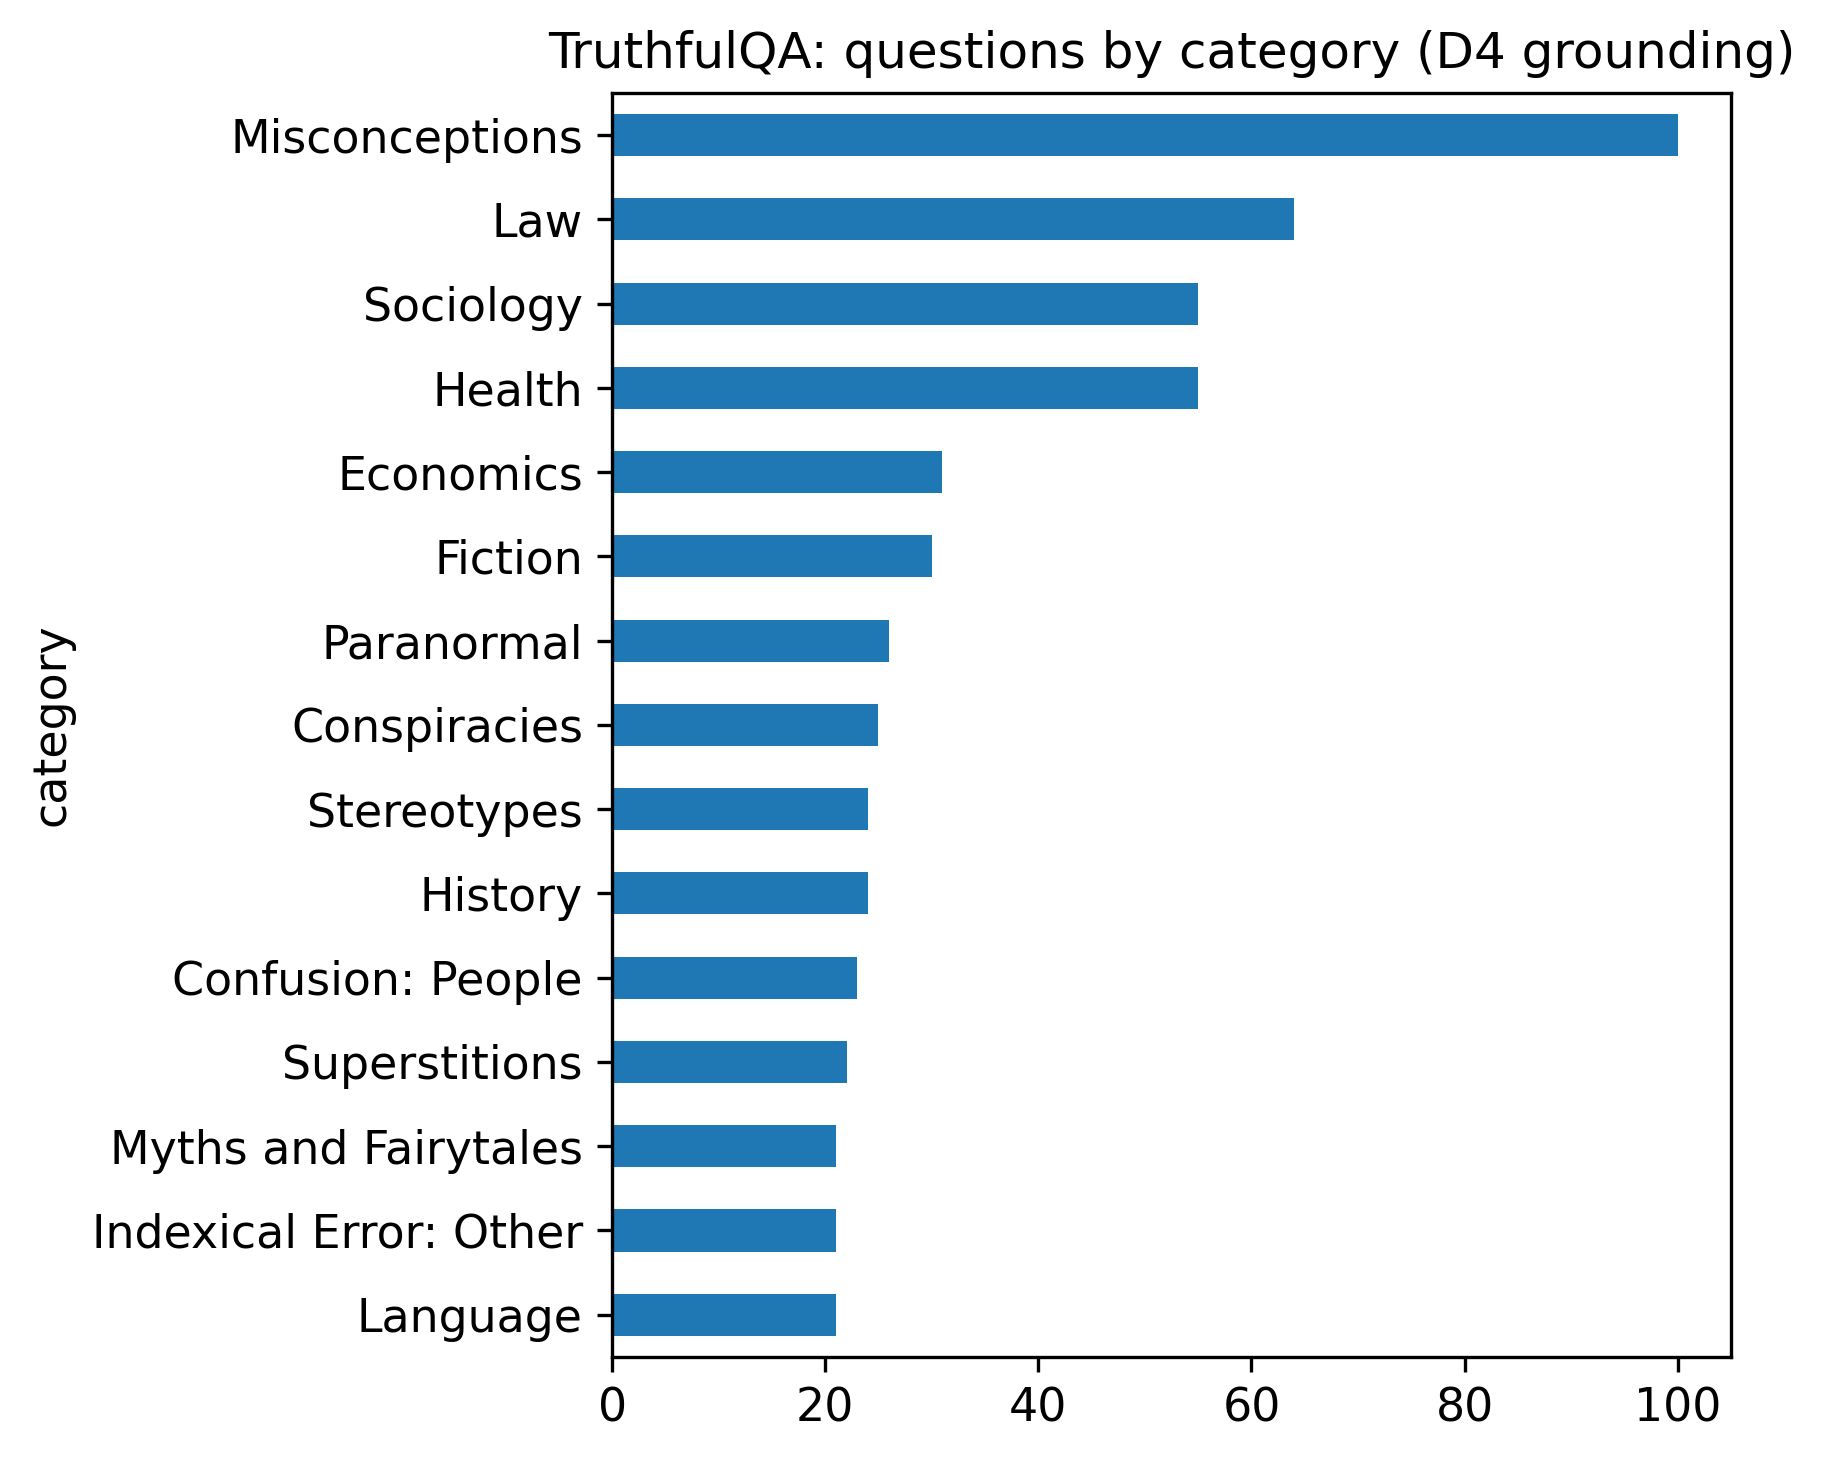

In [4]:
# TruthfulQA — use the 'generation' config, which has 'category' (the 'multiple_choice' config does not)
tqa = load_dataset('truthfulqa/truthful_qa', 'generation', split='validation')
df_tqa = pd.DataFrame({'category': tqa['category']})
top = df_tqa['category'].value_counts().head(15)
print('n questions =', len(df_tqa), '| n categories =', df_tqa['category'].nunique())
top.sort_values().plot(kind='barh', figsize=(6, 5),
                       title='TruthfulQA: questions by category (D4 grounding)')
plt.tight_layout(); savefig('d4_truthfulqa_categories'); plt.show()

### D3/D4 — Social bias: BBQ (optional)
Public: `walledai/BBQ`. Bias Benchmark for QA across nine social dimensions.


In [5]:
try:
    bbq = load_dataset('walledai/BBQ', split='test')
    print('BBQ loaded:', len(bbq), 'items | fields:', list(bbq.features)[:8])
except Exception as e:
    print('BBQ optional load skipped:', e)


README.md:   0%|          | 0.00/3.43k [00:00<?, ?B/s]

data/age-00000-of-00001.parquet:   0%|          | 0.00/77.6k [00:00<?, ?B/s]

data/disabilityStatus-00000-of-00001.par(…):   0%|          | 0.00/35.5k [00:00<?, ?B/s]

data/genderIdentity-00000-of-00001.parqu(…):   0%|          | 0.00/104k [00:00<?, ?B/s]

data/nationality-00000-of-00001.parquet:   0%|          | 0.00/71.0k [00:00<?, ?B/s]

...

Generating raceXGender split:   0%|          | 0/15960 [00:00<?, ? examples/s]

Generating religion split:   0%|          | 0/1200 [00:00<?, ? examples/s]

Generating ses split:   0%|          | 0/6864 [00:00<?, ? examples/s]

Generating sexualOrientation split:   0%|          | 0/864 [00:00<?, ? examples/s]

BBQ optional load skipped: Unknown split "test". Should be one of ['age', 'disabilityStatus', 'genderIdentity', 'nationality', 'physicalAppearance', 'raceEthnicity', 'raceXSes', 'raceXGender', 'religion', 'ses', 'sexualOrientation'].


### D5 — Adversarial & technical: real FGSM sweep
Computes a **real** accuracy-vs-epsilon curve on CIFAR-10 with a small model (the phenomenon behind the *Attacker* level).
For the *robustness-authenticity* capstone, RobustBench (`robustbench.github.io`) reports clean-vs-robust accuracy; pull those from the public leaderboard (do **not** hand-enter invented numbers).


In [6]:
!pip -q install torchattacks
import torch, torchvision, torchvision.transforms as T
from torch import nn
import torchattacks
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
tf = T.Compose([T.ToTensor()])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.0/142.0 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.7/178.7 kB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.2/144.2 kB 18.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.25.1 which is incompatible.
libpysal 4.14.1 requires requests>=2.32.0, but you have requests 2.25.1 which is incompatible.
bigframes 2.42.0 requires requests>=2.27.1, but you have requests 2.25.1 which is incompatible.
google-genai 2.10.0 requires requests<3.0.0,>=2.28.1, but

In [7]:
import torch, torchvision, torchvision.transforms as T
from torch import nn
import torchattacks
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
tf = T.Compose([T.ToTensor()])
test = torchvision.datasets.CIFAR10('.', train=False, download=True, transform=tf)
loader = torch.utils.data.DataLoader(test, batch_size=256, shuffle=False)
# Small CNN — train briefly OR load your own checkpoint. Here: a quick-train stub.
class Net(nn.Module):
    def __init__(s):
        super().__init__(); s.f=nn.Sequential(nn.Conv2d(3,32,3,1,1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,1,1),nn.ReLU(),nn.MaxPool2d(2),nn.Flatten(),nn.Linear(64*8*8,10))
    def forward(s,x): return s.f(x)
model = Net().to(dev)
# TODO: train `model` (a few epochs) or load a pretrained CIFAR-10 checkpoint before attacking.
print('NOTE: train or load a checkpoint into `model`, then run the sweep cell below.')


100%|██████████| 170M/170M [41:53<00:00, 67.8kB/s]


NOTE: train or load a checkpoint into `model`, then run the sweep cell below.


saved figures/d5_fgsm_sweep.jpg


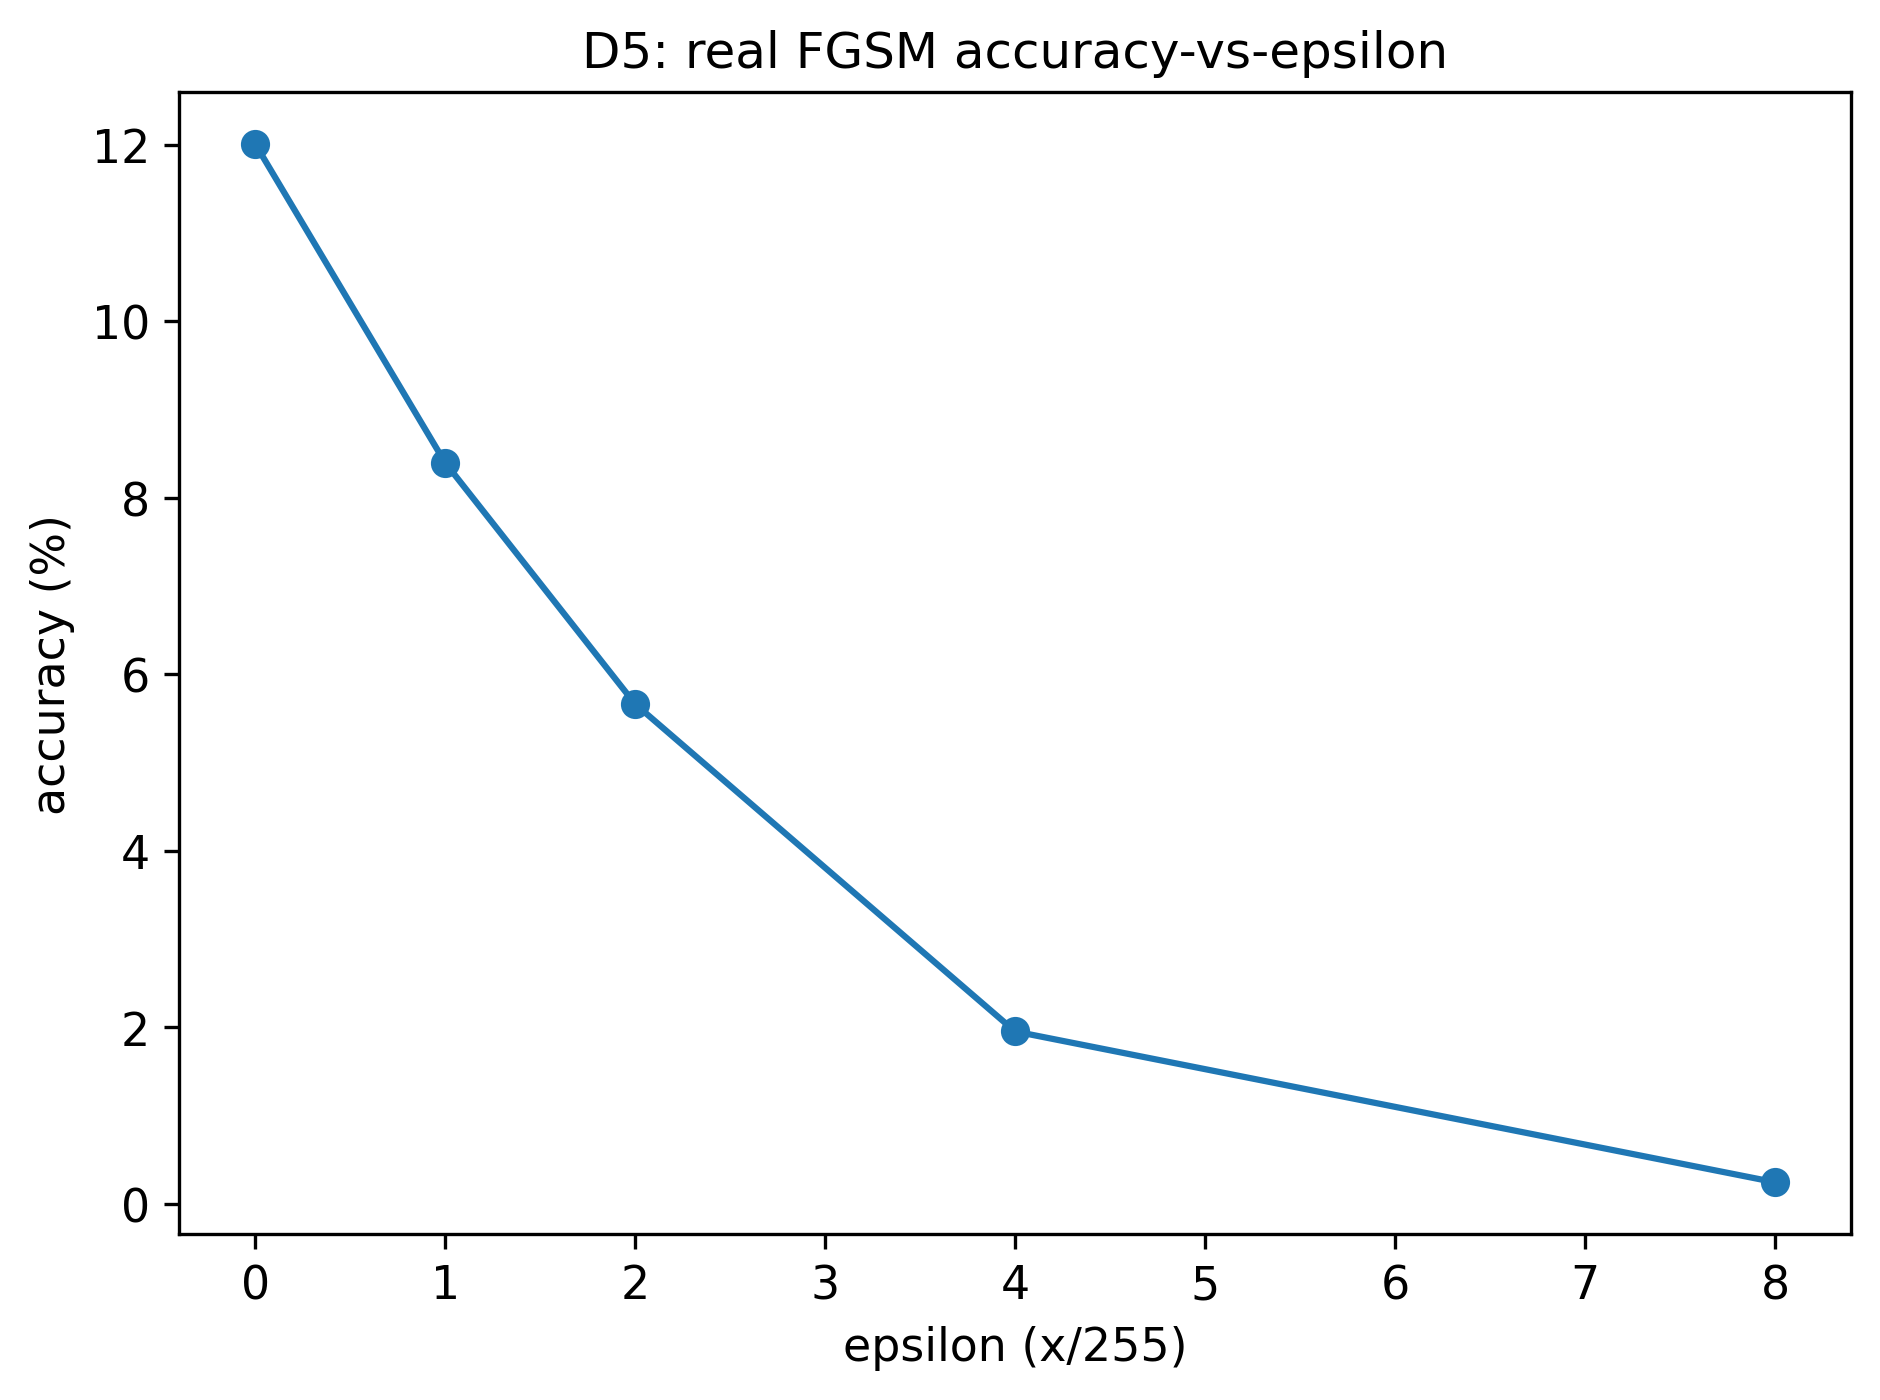

In [8]:
def accuracy_under_attack(model, loader, eps, n_batches=8):
    model.eval(); atk = torchattacks.FGSM(model, eps=eps) if eps>0 else None
    correct=total=0
    for i,(x,y) in enumerate(loader):
        if i>=n_batches: break
        x,y=x.to(dev),y.to(dev)
        if atk is not None: x = atk(x,y)
        with torch.no_grad(): correct += (model(x).argmax(1)==y).sum().item(); total += y.size(0)
    return correct/total
eps_grid = [0, 1/255, 2/255, 4/255, 8/255]
accs = [accuracy_under_attack(model, loader, e) for e in eps_grid]
plt.plot([e*255 for e in eps_grid], [a*100 for a in accs], 'o-')
plt.xlabel('epsilon (x/255)'); plt.ylabel('accuracy (%)'); plt.title('D5: real FGSM accuracy-vs-epsilon')
plt.tight_layout(); savefig('d5_fgsm_sweep'); plt.show()
pd.DataFrame({'eps_over_255':[e*255 for e in eps_grid],'accuracy':accs}).to_csv('tables/d5_fgsm_sweep.csv', index=False)


---
# TIER 1 — Construct grounding from educator/youth survey micro-data
**You provide the data.** Download the free micro-data + codebook and place the file(s) in your Drive folder:

- RAND American Educator Panels & American Youth Panel — https://www.rand.org/education-employment-infrastructure/survey-panels/aep/access-data.html (registration; some files restricted)
- Harvard *Educator AI Policies and Challenges* and Gallup *Teacher Workload and AI* — via the RAND survey catalog

Then complete the `ITEM_MAP` below using the **exact variable names from the codebook**.


In [9]:
SURVEY_FILE = os.path.join(DRIVE, 'rand_ai_teacher_panel.csv')  # <-- your downloaded file

# Map codebook variables -> AISL dimensions. Fill with REAL variable names from the codebook.
ITEM_MAP = {
  'D1_permission_norms':   [ 'TODO_var_policy_clarity', 'TODO_var_integrity_rules' ],
  'D2_data_privacy':       [ 'TODO_var_data_consent' ],
  'D3_threat_manip':       [ 'TODO_var_scam_deepfake_awareness' ],
  'D4_trust_calibration':  [ 'TODO_var_ai_reliability_belief' ],
  'D6_disposition_agency': [ 'TODO_var_confidence_using_ai', 'TODO_var_fear_or_avoidance' ],
}
ROLE_VAR = 'TODO_var_role'   # e.g., teacher/principal/district; or panel-of-origin
REVERSE_CODED = set()        # add any items that must be reverse-scored


In [10]:
def load_survey():
    if not os.path.exists(SURVEY_FILE):
        raise FileNotFoundError('Place the downloaded micro-data at '+SURVEY_FILE+' and complete ITEM_MAP.')
    if any('TODO' in v for vs in ITEM_MAP.values() for v in vs):
        raise ValueError('Complete ITEM_MAP with real codebook variable names before running Tier 1.')
    return pd.read_csv(SURVEY_FILE)

def analyze_tier1():
    import pingouin as pg; from factor_analyzer import FactorAnalyzer
    df = load_survey()
    # 1) per-dimension mean 'gap' score (higher = more competent/clear; define per codebook)
    dim_scores = {}
    for dim, items in ITEM_MAP.items():
        sub = df[items].apply(pd.to_numeric, errors='coerce')
        dim_scores[dim] = sub.mean(axis=1)
    S = pd.DataFrame(dim_scores)
    # 2) reliability (Cronbach alpha) per dimension with >=2 items
    alphas = {d:(pg.cronbach_alpha(df[items].apply(pd.to_numeric,errors='coerce').dropna())[0]
                 if len(items)>1 else np.nan) for d,items in ITEM_MAP.items()}
    pd.Series(alphas, name='cronbach_alpha').to_csv('tables/tier1_alpha.csv')
    # 3) dimensional structure (EFA)
    allitems = [i for its in ITEM_MAP.values() for i in its]
    X = df[allitems].apply(pd.to_numeric, errors='coerce').dropna()
    fa = FactorAnalyzer(n_factors=len(ITEM_MAP), rotation='varimax'); fa.fit(X)
    load = pd.DataFrame(fa.loadings_, index=allitems)
    load.to_csv('tables/tier1_efa_loadings.csv')
    plt.imshow(load.values, aspect='auto', cmap='viridis'); plt.colorbar(); plt.yticks(range(len(allitems)), allitems, fontsize=6)
    plt.title('Tier 1: EFA loadings (dimensional structure)'); plt.tight_layout(); savefig('fig_tier1_dimension_structure'); plt.show()
    # 4) gap by role
    if ROLE_VAR in df.columns:
        S[ROLE_VAR]=df[ROLE_VAR]
        S.groupby(ROLE_VAR).mean().T.plot(kind='bar', figsize=(8,4), title='Confusion-gap indicators by role')
        plt.ylabel('mean dimension score'); plt.tight_layout(); savefig('fig_tier1_gap_by_role'); plt.show()
    return S, alphas

# analyze_tier1()   # <-- uncomment after data + ITEM_MAP are in place


---
# Grounding matrix + manuscript exports
Builds the dimension → dataset → what-it-establishes → access table and the AISL×NeuralFortify alignment table used in the paper.


In [11]:
grounding = pd.DataFrame([
 ['D1 Permission & Norms','Tier1','RAND AEP / Harvard AI Policies','Policy vacuum & permission confusion','free (registration)'],
 ['D2 Data & Privacy','Tier1','RAND AEP','Consent/permission demand','free (registration)'],
 ['D3 Threat & Manipulation','Tier2','RealToxicityPrompts / AdvBench / BBQ','Toxic/manipulative generation is real & measurable','Apache-2.0 / open'],
 ['D4 Trust Calibration','Tier2','TruthfulQA / BBQ','Misconception susceptibility is measurable','Apache-2.0 / open'],
 ['D5 Adversarial & Technical','Tier2','RobustBench / (FGSM sweep here)','Attack success & defense gain measurable','open'],
 ['D6 Disposition & Agency','Tier1','RAND AEP / Gallup','Confidence vs. fear is measurable','free / public'],
], columns=['AISL dimension','Tier','Public dataset(s)','What it establishes','Access'])
grounding.to_csv('tables/grounding_matrix.csv', index=False)
with open('tables/grounding_matrix.tex','w') as f: f.write(grounding.to_latex(index=False, escape=True))
grounding


,AISL dimension,Tier,Public dataset(s),What it establishes,Access
0,D1 Permission & Norms,Tier1,RAND AEP / Harvard AI Policies,Policy vacuum & permission confusion,free (registration)
1,D2 Data & Privacy,Tier1,RAND AEP,Consent/permission demand,free (registration)
2,D3 Threat & Manipulation,Tier2,RealToxicityPrompts / AdvBench / BBQ,Toxic/manipulative generation is real & measur...,Apache-2.0 / open
3,D4 Trust Calibration,Tier2,TruthfulQA / BBQ,Misconception susceptibility is measurable,Apache-2.0 / open
4,D5 Adversarial & Technical,Tier2,RobustBench / (FGSM sweep here),Attack success & defense gain measurable,open
5,D6 Disposition & Agency,Tier1,RAND AEP / Gallup,Confidence vs. fear is measurable,free / public


In [12]:
alignment = pd.DataFrame([
 ['D1 Permission & Norms','Reflection journals; acceptable-use & disclosure framing'],
 ['D2 Data & Privacy','Username-only identity (no PII); privacy-by-architecture; consent records'],
 ['D3 Threat & Manipulation','Fooled module: Scammer->Detective->Scam-Buster on a real scam-text classifier'],
 ['D4 Trust Calibration','Confidence meters; before/after probabilities; verification prompts'],
 ['D5 Adversarial & Technical','Defend the Black Box: Attacker->Spy->Defender + adaptive robustness-authenticity test'],
 ['D6 Disposition & Agency','Mission role-play; self-efficacy & career-interest survey'],
], columns=['AISL dimension','NeuralFortify feature (real-model-backed)'])
alignment.to_csv('tables/alignment_matrix.csv', index=False)
with open('tables/alignment_matrix.tex','w') as f: f.write(alignment.to_latex(index=False, escape=True))
alignment


,AISL dimension,NeuralFortify feature (real-model-backed)
0,D1 Permission & Norms,Reflection journals; acceptable-use & disclosu...
1,D2 Data & Privacy,Username-only identity (no PII); privacy-by-ar...
2,D3 Threat & Manipulation,Fooled module: Scammer->Detective->Scam-Buster...
3,D4 Trust Calibration,Confidence meters; before/after probabilities;...
4,D5 Adversarial & Technical,Defend the Black Box: Attacker->Spy->Defender ...
5,D6 Disposition & Agency,Mission role-play; self-efficacy & career-inte...


---
## Notes for reproducibility & peer review
- Tier 2 cells run on public data and produce **computed** figures/tables (`figs/`, `tables/`).
- Tier 1 requires your downloaded micro-data + a completed `ITEM_MAP`; it then produces the coverage, reliability, EFA, and by-role figures the manuscript references.
- Pin package versions and set seeds before submission; report the exact dataset versions/commits.
- Tier 1 supports construct **relevance/coverage**; it is *not* a validated AISL scale. Validation = the NeuralFortify learner study (future work).
